# Selectivity Sweep - Correlation Verification
This notebook verifies that the synthetic metadata scrambling (derangement) perfectly hit the target correlation percentages (100%, 75%, 50%, 25%, 0%) for the `hm_clothes` tables.

It reads the original categories directly from the Qdrant payload file and cross-references them with the actual stored categories in each isolated PostgreSQL table.


In [1]:
import psycopg2
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Connect to PostgreSQL
conn = psycopg2.connect(
    dbname="vector_db",
    user="postgres",
    password="mysecretpassword",
    host="127.0.0.1",
    port="5433"
)

# 2. Load the original payloads
data_dir = os.path.join("ann-filtering-benchmark-datasets", "data")
payloads_path = os.path.join(data_dir, 'payloads.jsonl')

with open(payloads_path, 'r') as f:
    payloads = [json.loads(line) for line in f]

original_categories = [p.get('department_name', 'Unknown') for p in payloads]
print(f"Loaded {len(original_categories)} original categories.")


Loaded 105100 original categories.


In [2]:
tables = ["hm_clothes_100", "hm_clothes_75", "hm_clothes_50", "hm_clothes_25", "hm_clothes_0"]
results = []

for table in tables:
    # Fetch all categories from the table, ordered by vector_id to align with original payloads
    query = f"SELECT vector_id, category FROM {table} ORDER BY vector_id ASC"
    df_db = pd.read_sql(query, conn)
    
    # Compare
    db_categories = df_db['category'].tolist()
    
    # Calculate exact match percentage
    matches = sum(1 for orig, db in zip(original_categories, db_categories) if orig == db)
    match_percentage = (matches / len(original_categories)) * 100
    
    results.append({
        "Table": table,
        "Target Correlation (%)": int(table.split('_')[-1]),
        "Actual Correlation (%)": round(match_percentage, 2),
        "Exact Matches": matches
    })

results_df = pd.DataFrame(results)
display(results_df)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_44828\1056991621.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_db = pd.read_sql(query, conn)


,Table,Target Correlation (%),Actual Correlation (%),Exact Matches
0,hm_clothes_100,100,100.0,105100
1,hm_clothes_75,75,75.0,78825
2,hm_clothes_50,50,50.0,52550
3,hm_clothes_25,25,25.0,26275
4,hm_clothes_0,0,0.0,0


C:\Users\ASUS\AppData\Local\Temp\ipykernel_44828\1959679051.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_db = pd.read_sql(query, conn)


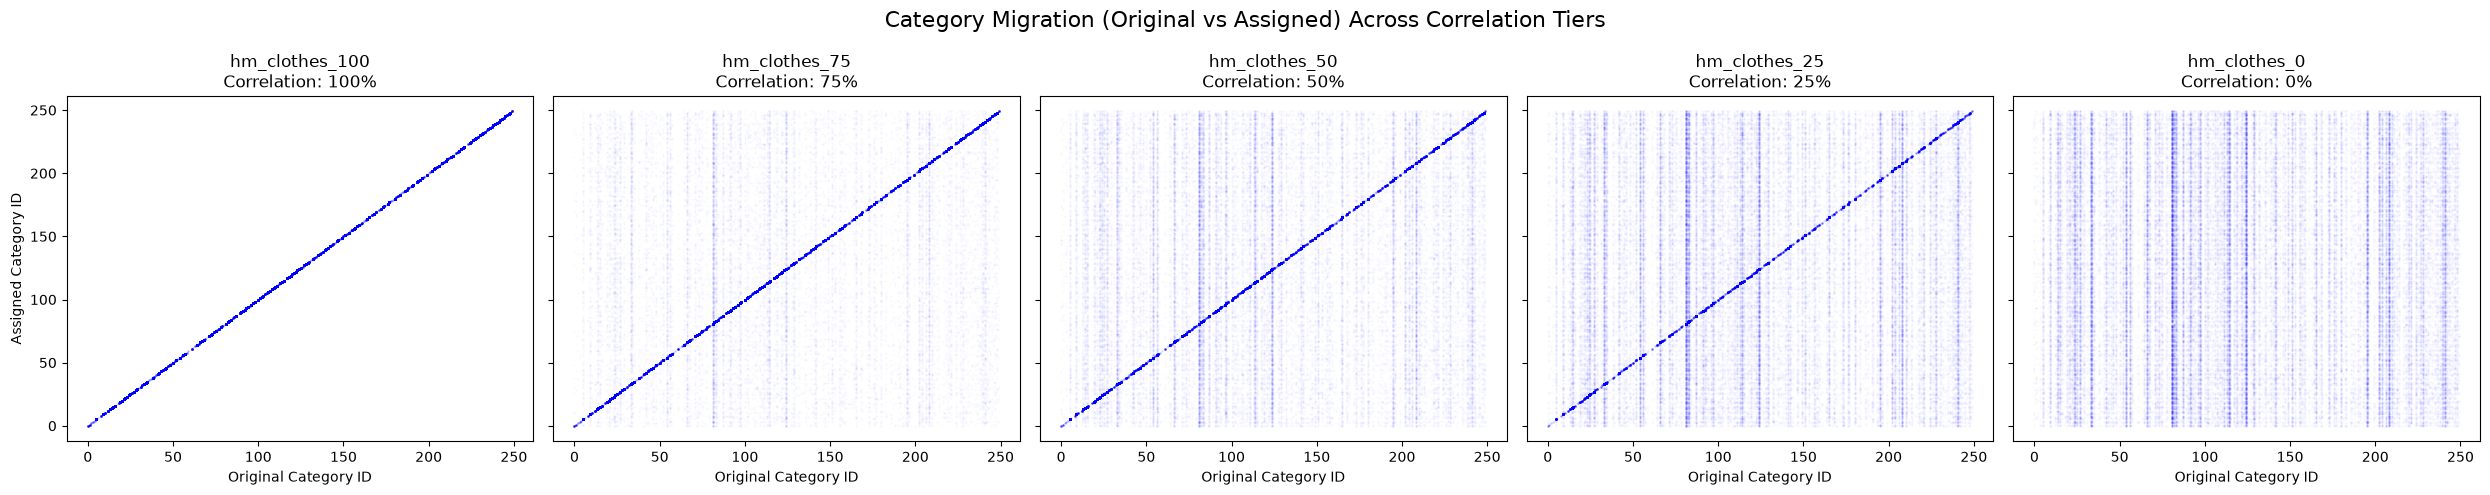

In [3]:
# Create a single figure with 5 subplots (scatter plots) for the 5 tables
fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharex=True, sharey=True)
fig.suptitle('Category Migration (Original vs Assigned) Across Correlation Tiers', fontsize=16)

# Create a mapping from category string to an integer for plotting
unique_categories = list(set(original_categories))
unique_categories.sort()
cat_to_int = {c: i for i, c in enumerate(unique_categories)}

orig_ints = [cat_to_int[c] for c in original_categories]

for idx, table in enumerate(tables):
    query = f"SELECT vector_id, category FROM {table} ORDER BY vector_id ASC"
    df_db = pd.read_sql(query, conn)
    db_categories = df_db['category'].tolist()
    
    # STRICT SCIENTIFIC VALIDATION: Ensure no unknown/corrupted categories were inserted
    unknown_cats = set(db_categories) - set(unique_categories)
    assert len(unknown_cats) == 0, f"CRITICAL ERROR: Found corrupted/unknown categories in {table}: {unknown_cats}"
    
    db_ints = [cat_to_int[c] for c in db_categories]
    
    ax = axes[idx]
    # Use alpha and small size to show density of 105k points
    ax.scatter(orig_ints, db_ints, alpha=0.01, s=1, color='blue')
    
    target_pct = int(table.split('_')[-1])
    ax.set_title(f"{table}\nCorrelation: {target_pct}%")
    ax.set_xlabel('Original Category ID')
    if idx == 0:
        ax.set_ylabel('Assigned Category ID')
    
    # Plotting complete without reference lines


plt.tight_layout()
plt.show()
